In [2]:
# Student Query Classification Project
import sys, subprocess, os, re, warnings, importlib
warnings.filterwarnings("ignore")

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scikit-learn": "sklearn",
    "nltk": "nltk",
    "wordcloud": "wordcloud",
    "joblib": "joblib",
    "openpyxl": "openpyxl",
    "flask": "flask",
}

for pip_name, import_name in packages.items():
    try:
        importlib.import_module(import_name)
    except ImportError:
        print("Installing:", pip_name)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

try:
    import xgboost
    XGBOOST_AVAILABLE = True
except Exception:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
        import xgboost
        XGBOOST_AVAILABLE = True
    except Exception:
        XGBOOST_AVAILABLE = False

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.utils.class_weight import compute_sample_weight, compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import joblib

In [4]:
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

stop_words = set(stopwords.words("english"))

# keeping question words that are helpful in classification
words_to_keep = {"how", "what", "why", "when", "where", "which", "can", "could",
                 "should", "would", "is", "are", "do", "does"}
stop_words = stop_words - words_to_keep

lemmatizer = WordNetLemmatizer()

In [5]:
# False = 3 classes (Academic, Course Query, Technical)
# True  = 2 classes (Course Query gets merged into Academic)
BINARY_MODE = False

RANDOM_STATE = 42
TEST_SIZE = 0.20

MIN_DF = 2
TREE_FEATURES = 3000

OUTPUT_FOLDER = "student_query_project_output"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

print("BINARY_MODE =", BINARY_MODE)
print("TEST_SIZE =", TEST_SIZE)
print("TREE_FEATURES =", TREE_FEATURES)

BINARY_MODE = False
TEST_SIZE = 0.2
TREE_FEATURES = 3000


In [7]:
# finding excel file
possible_files = [
    "Student Queries Data.xlsx",
    "Student_Queries_Data.xlsx",
    "/mnt/data/Student Queries Data.xlsx",
]

file_path = None
for path in possible_files:
    if os.path.exists(path):
        file_path = path
        break

print("Dataset found:", file_path)

Dataset found: Student Queries Data.xlsx


In [8]:
df = pd.read_excel(file_path)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Shape: (22094, 3)
Columns: ['query', 'queryType', 'answer']


,query,queryType,answer
0,explain recession,Academic,<!--StartFragment-->A recession is a macroecon...
1,define types of economics names,technical,<!--StartFragment-->Microeconomics is&nbsp;the...
2,wish you a happy new year mam,Academic,Happy New Year to you too&nbsp;
3,Sir your lectures are really helpful can u ple...,Course Query,"<!--StartFragment--><h4 style=""box-sizing: bor..."
4,are there any seperate marks for diagram in th...,Course Query,No separate marks allocated...nor in Exam u wi...


In [9]:
for column in ["query", "queryType"]:
    if column not in df.columns:
        raise ValueError(f"Column '{column}' not found. Columns are: {df.columns.tolist()}")

In [10]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nMissing values:")
print(df.isnull().sum())
print("\nOriginal queryType counts:")
print(df["queryType"].value_counts(dropna=False))

Rows: 22094
Columns: 3

Missing values:
query          2
queryType      0
answer       351
dtype: int64

Original queryType counts:
Course Query    11892
Academic         7415
technical        2078
Technical         709
Name: queryType, dtype: int64


In [11]:
data = df[["query", "queryType"]].copy()
data = data.rename(columns={"query": "Query", "queryType": "Category"})

In [12]:
data["Query"] = data["Query"].fillna("").astype(str).str.strip()
data["Category"] = data["Category"].fillna("").astype(str).str.strip()

data = data[(data["Query"] != "") & (data["Category"] != "")].copy()
print("Rows after removing missing values:", len(data))

Rows after removing missing values: 22091


In [13]:
# fixing labels
def standardize_category(label):
    label_clean = str(label).strip().lower()
    if label_clean == "technical":
        return "Technical"
    if label_clean == "academic":
        return "Academic"
    if label_clean == "course query":
        return "Course Query"
    return str(label).strip()

data["Category"] = data["Category"].apply(standardize_category)

In [14]:
if BINARY_MODE:
    print("Binary mode: Course Query -> Academic")
    data["Category"] = data["Category"].replace({"Course Query": "Academic"})
else:
    print("Three-class mode.")

Three-class mode.


In [16]:
# no duplicates
before = len(data)
data = data.drop_duplicates(subset=["Query", "Category"]).reset_index(drop=True)
print("Duplicates removed:", before - len(data))
print("Rows left:", len(data))

label_counts = data.groupby("Query")["Category"].nunique()
print("Queries that appear with more than one label:", int((label_counts > 1).sum()))

Duplicates removed: 0
Rows left: 21527
Queries that appear with more than one label: 99


In [17]:
def clean_text(text):
    text = str(text).lower()

    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"&[a-zA-Z0-9#]+;", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    # regex instead of punkt so no extra download
    tokens = re.findall(r"[a-zA-Z]+", text)

    cleaned_tokens = []
    for token in tokens:
        if token in stop_words or len(token) <= 1:
            continue
        try:
            token = lemmatizer.lemmatize(token)
        except Exception:
            pass
        cleaned_tokens.append(token)

    return " ".join(cleaned_tokens)

In [18]:
data["Clean_Query"] = data["Query"].apply(clean_text)

data = data[data["Clean_Query"].str.strip() != ""].reset_index(drop=True)

display(data[["Query", "Clean_Query", "Category"]].head(10))

,Query,Clean_Query,Category
0,explain recession,explain recession,Academic
1,define types of economics names,define type economics name,Technical
2,wish you a happy new year mam,wish happy new year mam,Academic
3,Sir your lectures are really helpful can u ple...,sir lecture are really helpful can please answ...,Course Query
4,are there any seperate marks for diagram in th...,are seperate mark diagram exam,Course Query
5,Is Fiancial Statement prepare for Business pur...,is fiancial statement prepare business purpose...,Academic
6,"Sir, please refer Session 3- Slide No. 32 ,33...",sir please refer session slide recognition int...,Technical
7,Good Evening sir. I did not understand what BA...,good evening sir understand what barnacle mean...,Academic
8,"Sir, Please tell us whether we have to memoriz...",sir please tell u whether memorize entire chap...,Course Query
9,"Sir, Please guide us how to prepare for the ex...",sir please guide u how prepare examination,Course Query


In [19]:
# dataset info
print("Rows:", len(data))
print("Columns:", len(data.columns))
print("\nClass distribution:")
print(data["Category"].value_counts())
print("\nClass percentages:")
print((data["Category"].value_counts(normalize=True) * 100).round(2))

Rows: 21519
Columns: 3

Class distribution:
Course Query    11449
Academic         7349
Technical        2721
Name: Category, dtype: int64

Class percentages:
Course Query    53.20
Academic        34.15
Technical       12.64
Name: Category, dtype: float64


In [20]:
cleaned_file = os.path.join(OUTPUT_FOLDER, "clean_student_queries.xlsx")
data.to_excel(cleaned_file, index=False)
print("Saved:", cleaned_file)

Saved: student_query_project_output/clean_student_queries.xlsx


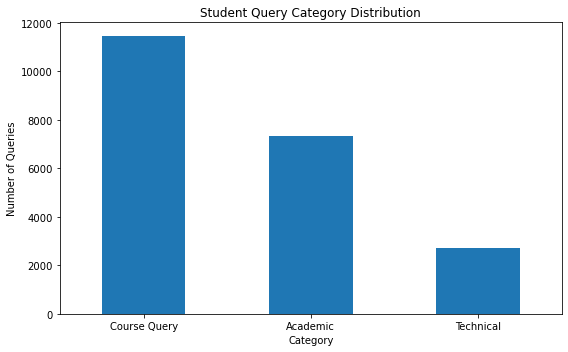

In [21]:
plt.figure(figsize=(8, 5))
data["Category"].value_counts().plot(kind="bar")
plt.title("Student Query Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Queries")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

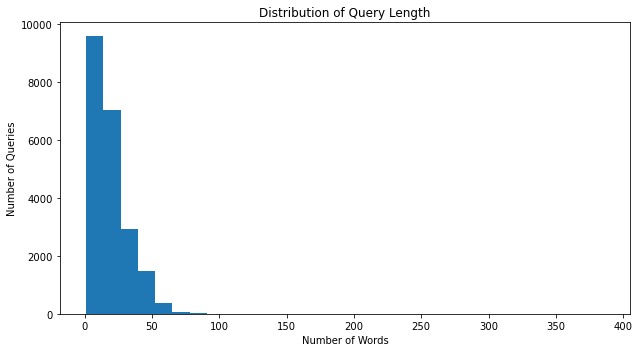

Query length stats:
count    21519.000000
mean        18.933408
std         13.548887
min          1.000000
25%          9.000000
50%         15.000000
75%         25.000000
max        386.000000
Name: Query_Length, dtype: float64


In [22]:
data["Query_Length"] = data["Clean_Query"].apply(lambda x: len(x.split()))

plt.figure(figsize=(9, 5))
plt.hist(data["Query_Length"], bins=30)
plt.title("Distribution of Query Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Queries")
plt.tight_layout()
plt.show()

print("Query length stats:")
print(data["Query_Length"].describe())

In [23]:
# most common or repeating words
all_words = []
for text in data["Clean_Query"]:
    all_words.extend(text.split())

word_counts = Counter(all_words)
top_words_df = pd.DataFrame(word_counts.most_common(20), columns=["Word", "Frequency"])

print("Top 20 words:")
display(top_words_df)

Top 20 words:


,Word,Frequency
0,is,15819
1,can,7341
2,question,7158
3,sir,6593
4,please,5937
5,what,5118
6,are,5038
7,assignment,4664
8,how,3755
9,mam,3675


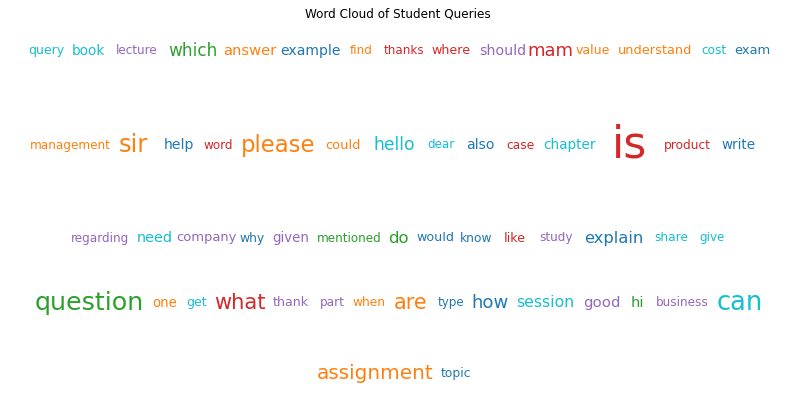

In [24]:
# word cloud 
import random

def draw_cloud(text, title, width=1200, height=600, max_words=100):
    try:
        wc = WordCloud(width=width, height=height, background_color="white", max_words=max_words).generate(text)
        plt.figure(figsize=(14, 7))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(title)
        plt.show()
        return
    except Exception:
        pass

    words = Counter(text.split()).most_common(60)
    if len(words) == 0:
        return
    top = words[0][1]
    random.Random(42).shuffle(words)

    canvas_w = 900
    rows, row, row_w, row_h = [], [], 0, 0
    for word, count in words:
        size = 10 + 34 * (count / top)
        w = len(word) * size * 0.6 + 14
        if row_w + w > canvas_w and row:
            rows.append((row, row_h))
            row, row_w, row_h = [], 0, 0
        row.append((word, size, w))
        row_w += w
        row_h = max(row_h, size * 1.5)
    rows.append((row, row_h))

    total_h = sum(h for _, h in rows)
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.set_xlim(0, canvas_w)
    ax.set_ylim(0, total_h)
    ax.axis("off")

    y = total_h
    colors = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e", "#17becf"]
    for row_words, h in rows:
        row_total = sum(w for _, _, w in row_words)
        x = (canvas_w - row_total) / 2
        y -= h
        for i, (word, size, w) in enumerate(row_words):
            ax.text(x + w / 2, y + h / 2, word, fontsize=size, ha="center", va="center",
                    color=colors[(len(word) + i) % len(colors)])
            x += w
    ax.set_title(title)
    plt.show()


all_text = " ".join(data["Clean_Query"].tolist())

if all_text.strip():
    draw_cloud(all_text, "Word Cloud of Student Queries")

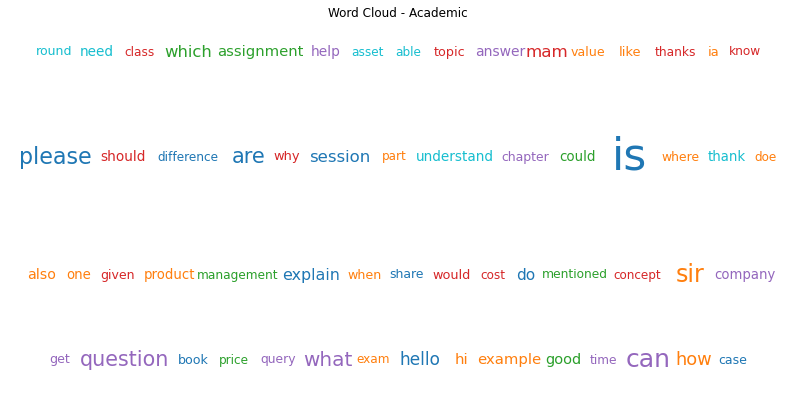

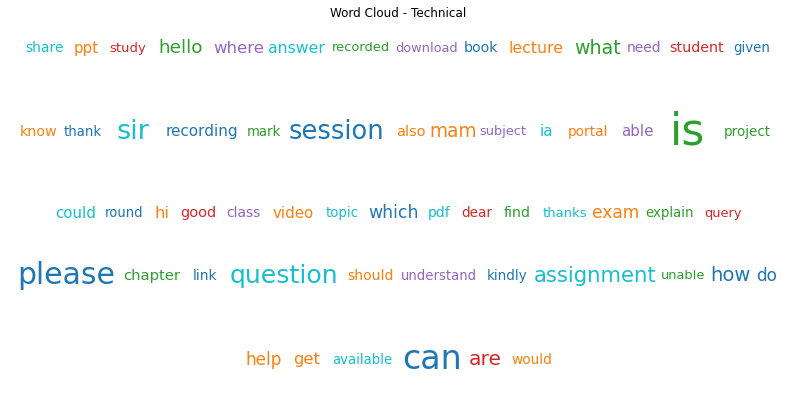

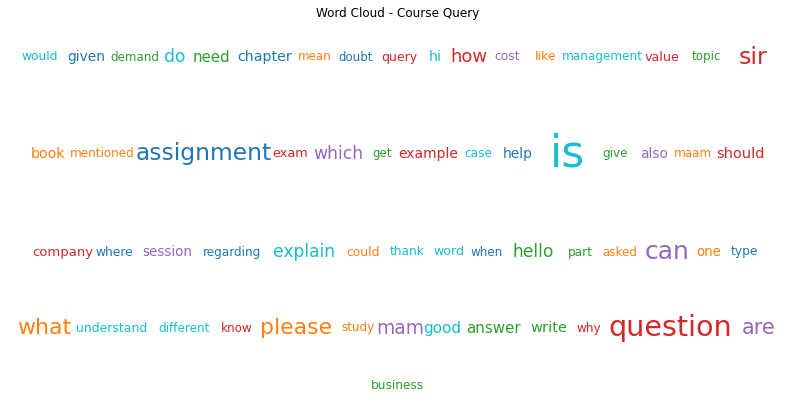

In [26]:
# word clod of all the categories of the queries
for category in data["Category"].unique():
    category_text = " ".join(data.loc[data["Category"] == category, "Clean_Query"].tolist())

    if category_text.strip():
        draw_cloud(category_text, f"Word Cloud - {category}", width=1000, height=500, max_words=80)

In [27]:
X_text = data["Clean_Query"]
y_text = data["Category"]

In [28]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

print(dict(enumerate(label_encoder.classes_)))

{0: 'Academic', 1: 'Course Query', 2: 'Technical'}


In [29]:
# train test split
train_text, test_text, y_train, y_test = train_test_split(
    X_text, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(train_text))
print("Testing samples:", len(test_text))

Training samples: 17215
Testing samples: 4304


In [30]:
# bag of words to compare
bow_vectorizer = CountVectorizer(max_features=TREE_FEATURES, ngram_range=(1, 2))

X_train_bow = bow_vectorizer.fit_transform(train_text)
X_test_bow = bow_vectorizer.transform(test_text)

print("BoW train shape:", X_train_bow.shape)
print("BoW test shape:", X_test_bow.shape)

BoW train shape: (17215, 3000)
BoW test shape: (4304, 3000)


In [31]:
# tf-idf
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=MIN_DF, sublinear_tf=True)
X_tr = tfidf_vectorizer.fit_transform(train_text)
X_te = tfidf_vectorizer.transform(test_text)

# random forest and xgboost
tfidf_small = TfidfVectorizer(ngram_range=(1, 2), min_df=MIN_DF, max_features=TREE_FEATURES, sublinear_tf=True)
X_tr_t = tfidf_small.fit_transform(train_text)
X_te_t = tfidf_small.transform(test_text)

print("TF-IDF (linear) train shape:", X_tr.shape)
print("TF-IDF (linear) test shape:", X_te.shape)
print("TF-IDF (trees) train shape:", X_tr_t.shape)
print("TF-IDF (trees) test shape:", X_te_t.shape)

TF-IDF (linear) train shape: (17215, 42643)
TF-IDF (linear) test shape: (4304, 42643)
TF-IDF (trees) train shape: (17215, 3000)
TF-IDF (trees) test shape: (4304, 3000)


In [32]:
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Number of TF-IDF features:", len(feature_names))
print("First 30 features:")
print(feature_names[:30])

Number of TF-IDF features: 42643
First 30 features:
['aa' 'aa raha' 'aadhar' 'aaj' 'aakash' 'aam' 'aam didnt' 'aap' 'aashna'
 'aaya' 'ab' 'abbreviation' 'abc' 'abc analysis' 'abc company'
 'abc corporation' 'abc ltd' 'abc pvt' 'abc xyz' 'abhijeet'
 'abhijeet gupta' 'abhinav' 'abhishek' 'abhishek tripathi' 'abide'
 'ability' 'able' 'able able' 'able access' 'able align']


Variance explained by 2 components: 0.0068


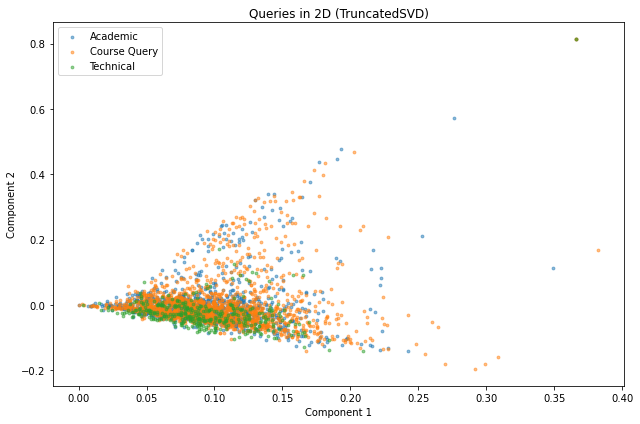

In [33]:
# dimensionality reduced
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
svd_points = svd.fit_transform(X_tr)

print("Variance explained by 2 components:", round(svd.explained_variance_ratio_.sum(), 4))

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(svd_points), size=min(3000, len(svd_points)), replace=False)

plt.figure(figsize=(9, 6))
for number, label in enumerate(label_encoder.classes_):
    mask = y_train[sample_idx] == number
    plt.scatter(svd_points[sample_idx][mask, 0], svd_points[sample_idx][mask, 1], s=8, alpha=0.5, label=label)
plt.title("Queries in 2D (TruncatedSVD)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
# helpers to avoid pasting the same metric everytime
def get_scores(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

def show_scores(scores):
    print("Accuracy :", round(scores["Accuracy"], 4))
    print("Precision:", round(scores["Precision"], 4))
    print("Recall   :", round(scores["Recall"], 4))
    print("F1 Score :", round(scores["F1"], 4))

# stores each model and what it needs picking the best model becomes easier
trained = {}
results = []

def register(name, model, preds, X_train, X_test, vectorizer):
    trained[name] = {"model": model, "preds": preds, "X_train": X_train, "X_test": X_test, "vectorizer": vectorizer}
    results.append(get_scores(name, y_test, preds))
    show_scores(results[-1])

In [35]:
# logistic regression 
print("LOGISTIC REGRESSION")

lr = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE, class_weight="balanced")
lr.fit(X_tr, y_train)

register("Logistic Regression", lr, lr.predict(X_te),
         X_tr, X_te, tfidf_vectorizer)

LOGISTIC REGRESSION
Accuracy : 6.115e-01
Precision: 0.627
Recall   : 0.6115
F1 Score : 0.6169


In [36]:
# linear svm 
print("LINEAR SVM")

svm = LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE)
svm.fit(X_tr, y_train)

register("Linear SVM", svm, svm.predict(X_te),
         X_tr, X_te, tfidf_vectorizer)

LINEAR SVM
Accuracy : 0.6106
Precision: 0.6072
Recall   : 0.6106
F1 Score : 0.6085


In [37]:
# random forest and tf-idf matrix 
print("RANDOM FOREST")

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced_subsample"
)
rf.fit(X_tr_t, y_train)

register("Random Forest", rf, rf.predict(X_te_t),
         X_tr_t, X_te_t, tfidf_small)

RANDOM FOREST
Accuracy : 0.625
Precision: 0.6108
Recall   : 0.625
F1 Score : 0.6094


In [38]:
# xgboost
xgb = None

if XGBOOST_AVAILABLE:
    print("XGBOOST")
    try:
        from xgboost import XGBClassifier

        xgb = XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.5,
            tree_method="hist",
            random_state=RANDOM_STATE,
            eval_metric="mlogloss",
            n_jobs=-1
        )

        xgb_weights = compute_sample_weight("balanced", y_train)
        xgb.fit(X_tr_t, y_train, sample_weight=xgb_weights)

        register("XGBoost", xgb, xgb.predict(X_te_t),
                 X_tr_t, X_te_t, tfidf_small)

    except Exception as e:
        xgb = None
        print("XGBoost couldn't run, skipping it. Reason:", e)
else:
    print("XGBoost isn't installed, skipping it.")

XGBOOST
Accuracy : 0.5962
Precision: 0.6151
Recall   : 0.5962
F1 Score : 0.6026


In [39]:
# neural network 
print("NEURAL NETWORK (MLP)")

mlp = MLPClassifier(
    hidden_layer_sizes=(128,),
    alpha=1e-4,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=3,
    max_iter=30,
    random_state=RANDOM_STATE
)
mlp.fit(X_tr, y_train)

register("Neural Network (MLP)", mlp, mlp.predict(X_te),
         X_tr, X_te, tfidf_vectorizer)

NEURAL NETWORK (MLP)
Accuracy : 6.373e-01
Precision: 0.6245
Recall   : 0.6373
F1 Score : 0.6225


In [40]:
first_df = pd.DataFrame(results).sort_values(by="F1", ascending=False).reset_index(drop=True)

print("INITIAL MODEL COMPARISON")
display(first_df.style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}))

INITIAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,Neural Network (MLP),0.6373,0.6245,0.6373,0.6225
1,Logistic Regression,0.6115,0.6270,0.6115,0.6169
2,Random Forest,0.6250,0.6108,0.6250,0.6094
3,Linear SVM,0.6106,0.6072,0.6106,0.6085
4,XGBoost,0.5962,0.6151,0.5962,0.6026


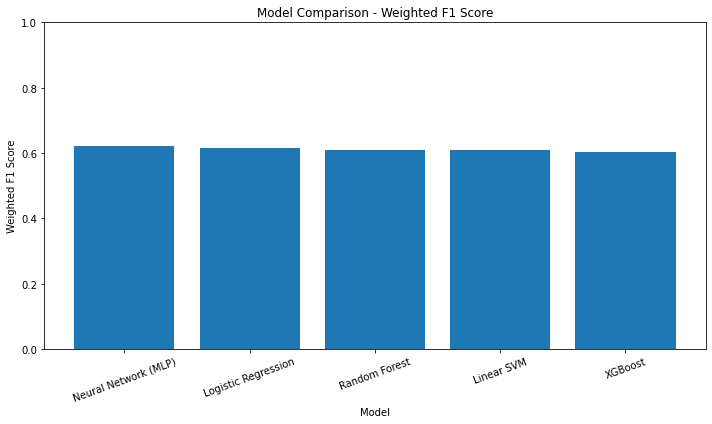

In [41]:
# model comparison graph
plt.figure(figsize=(10, 6))
plt.bar(first_df["Model"], first_df["F1"])
plt.title("Model Comparison - Weighted F1 Score")
plt.xlabel("Model")
plt.ylabel("Weighted F1 Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [42]:
# tuning logistic regression
print("TUNING LOGISTIC REGRESSION")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_grid = {"C": [0.5, 1, 2, 5, 10]}

lr_gs = GridSearchCV(
    LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    lr_grid,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)
lr_gs.fit(X_tr, y_train)

tuned_lr = lr_gs.best_estimator_

print("Best parameters:", lr_gs.best_params_)
print("Best CV F1:", round(lr_gs.best_score_, 4))

TUNING LOGISTIC REGRESSION
Best parameters: {'C': 1}
Best CV F1: 6.079e-01


In [43]:
# tuning svm
print("TUNING LINEAR SVM")

svm_grid = {"C": [0.05, 0.1, 0.2, 0.5, 1]}

svm_gs = GridSearchCV(
    LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
    svm_grid,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)
svm_gs.fit(X_tr, y_train)

tuned_svm = svm_gs.best_estimator_

print("Best parameters:", svm_gs.best_params_)
print("Best CV F1:", round(svm_gs.best_score_, 4))

TUNING LINEAR SVM
Best parameters: {'C': 0.1}
Best CV F1: 0.6163


In [44]:
# evaluate the tuned models on the test set
print("TUNED LOGISTIC REGRESSION")
register("Tuned Logistic Regression", tuned_lr, tuned_lr.predict(X_te),
         X_tr, X_te, tfidf_vectorizer)

print("\nTUNED LINEAR SVM")
register("Tuned Linear SVM", tuned_svm, tuned_svm.predict(X_te),
         X_tr, X_te, tfidf_vectorizer)

TUNED LOGISTIC REGRESSION
Accuracy : 0.6115
Precision: 0.627
Recall   : 0.6115
F1 Score : 0.6169

TUNED LINEAR SVM
Accuracy : 0.6296
Precision: 0.6262
Recall   : 0.6296
F1 Score : 0.6255


In [46]:
final_df = pd.DataFrame(results).sort_values(by="F1", ascending=False).reset_index(drop=True)

print("FINAL MODEL COMPARISON")
display(final_df.style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,Tuned Linear SVM,0.6296,0.6262,0.6296,0.6255
1,Neural Network (MLP),0.6373,0.6245,0.6373,0.6225
2,Logistic Regression,0.6115,0.6270,0.6115,0.6169
3,Tuned Logistic Regression,0.6115,0.6270,0.6115,0.6169
4,Tuned Random Forest,0.6138,0.6159,0.6138,0.6133
5,Random Forest,0.6250,0.6108,0.6250,0.6094
6,Linear SVM,0.6106,0.6072,0.6106,0.6085
7,XGBoost,0.5962,0.6151,0.5962,0.6026


In [48]:
# grab everything for the best model
if 'final_df' in globals() and not final_df.empty:
    best_model_name = final_df.iloc[0]["Model"]
elif 'first_df' in globals() and not first_df.empty:
    best_model_name = first_df.iloc[0]["Model"]
else:
    raise ValueError("No evaluation results found. Please run the model training cells first.")

# Verify the model exists in the trained dictionary
if best_model_name not in trained:
    # Fallback to the first available model in `trained` if the name doesn't match
    best_model_name = list(trained.keys())[0]

print(f"Selected best model: {best_model_name}")

best = trained[best_model_name]

best_model = best["model"]
best_preds = best["preds"]
best_Xtr = best["X_train"]
best_Xte = best["X_test"]
best_vec = best["vectorizer"]

Selected best model: Tuned Linear SVM


In [49]:
# final evaluation
final_scores = get_scores(best_model_name, y_test, best_preds)

final_accuracy = final_scores["Accuracy"]
final_precision = final_scores["Precision"]
final_recall = final_scores["Recall"]
final_f1 = final_scores["F1"]

print("FINAL EVALUATION")
print("Best Model :", best_model_name)
print("Accuracy   :", round(final_accuracy, 4))
print("Precision  :", round(final_precision, 4))
print("Recall     :", round(final_recall, 4))
print("F1 Score   :", round(final_f1, 4))

FINAL EVALUATION
Best Model : Tuned Linear SVM
Accuracy   : 0.6296
Precision  : 0.6262
Recall     : 0.6296
F1 Score   : 0.6255


In [50]:
# classification report
class_names = label_encoder.classes_

report_text = classification_report(y_test, best_preds, target_names=class_names, zero_division=0)

print("Classification Report:")
print(report_text)

Classification Report:
              precision    recall  f1-score   support

    Academic       0.58      0.48      0.52      1470
Course Query       0.70      0.76      0.73      2290
   Technical       0.44      0.49      0.47       544

    accuracy                           0.63      4304
   macro avg       0.57      0.58      0.57      4304
weighted avg       0.63      0.63      0.63      4304



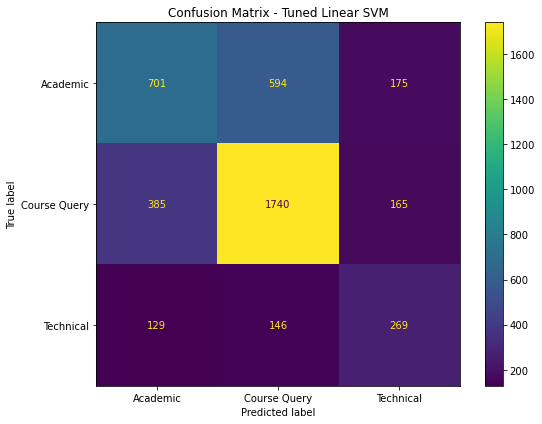

In [51]:
# confusion matrix
cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(values_format="d", ax=plt.gca())
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [52]:
# ROC-AUC
roc_auc = None

try:
    if hasattr(best_model, "predict_proba"):
        scores = best_model.predict_proba(best_Xte)
    elif hasattr(best_model, "decision_function"):
        scores = best_model.decision_function(best_Xte)
    else:
        scores = None

    if scores is not None:
        if len(class_names) == 2:
            # binary, use positive class score
            positive_scores = scores[:, 1] if scores.ndim == 2 else scores
            roc_auc = roc_auc_score(y_test, positive_scores)
        else:
            # multiclass, one vs rest (works for svm scores too)
            y_test_bin = label_binarize(y_test, classes=list(range(len(class_names))))
            roc_auc = roc_auc_score(y_test_bin, scores, average="weighted")

        print("Weighted ROC-AUC:", round(roc_auc, 4))
    else:
        print("ROC-AUC not available for this model.")

except Exception as e:
    roc_auc = None
    print("ROC-AUC couldn't be calculated. Reason:", e)

Weighted ROC-AUC: 0.76


In [53]:
# cross validation of the best model
print("CROSS-VALIDATION")

try:
    cv_scores = cross_val_score(
        best_model,
        best_Xtr,
        y_train,
        cv=cv,
        scoring="f1_weighted",
        n_jobs=1
    )

    print("CV F1 scores:", np.round(cv_scores, 4))
    print("Mean CV F1:", round(cv_scores.mean(), 4))
    print("CV Std:", round(cv_scores.std(), 4))

except Exception as e:
    print("Cross-validation couldn't finish. Reason:", e)

CROSS-VALIDATION
CV F1 scores: [0.6214 0.6191 0.6139 0.6105 0.6165]
Mean CV F1: 0.6163
CV Std: 0.0038


In [54]:
# error synthesis
test_indices = test_text.index

error_analysis = pd.DataFrame(
    {
        "Query": data.loc[test_indices, "Query"].values,
        "Actual": label_encoder.inverse_transform(y_test),
        "Predicted": label_encoder.inverse_transform(best_preds),
    },
    index=test_indices
)

misclassified = error_analysis[error_analysis["Actual"] != error_analysis["Predicted"]].copy()

print("Total test queries:", len(error_analysis))
print("Misclassified:", len(misclassified))
print("Error rate:", round(len(misclassified) / len(error_analysis), 4))

# which mistakes happen most
print("\nMost common mistakes (actual -> predicted):")
print(misclassified.groupby(["Actual", "Predicted"]).size().sort_values(ascending=False))

print("\nSample misclassified queries:")
display(misclassified.head(20))

Total test queries: 4304
Misclassified: 1594
Error rate: 0.3704

Most common mistakes (actual -> predicted):
Actual        Predicted   
Academic      Course Query    594
Course Query  Academic        385
Academic      Technical       175
Course Query  Technical       165
Technical     Course Query    146
              Academic        129
dtype: int64

Sample misclassified queries:


,Query,Actual,Predicted
10446,My query is suppose I completed my online clas...,Academic,Technical
19689,"mam, I saw ur recorded lecture of sale of good...",Course Query,Academic
4046,"Hello Professor, as you explained that for Tre...",Academic,Course Query
15192,"Hi sir, in the monitoring and controlling sess...",Course Query,Technical
9508,"sir, can you plz explain the significance of...",Academic,Course Query
2038,Dear ma'am \nGreetings!\nIn yesterday's Uber E...,Academic,Course Query
4671,How will you decide on the recruitment strateg...,Academic,Course Query
4063,kindly share the whatsapp link for students wi...,Academic,Technical
17987,hello\nmanagement is Science as well as art\ns...,Course Query,Technical
2365,Sir in the illustration No. 5 which explain th...,Academic,Course Query


In [55]:
misclassified_file = os.path.join(OUTPUT_FOLDER, "misclassified_queries.xlsx")
misclassified.to_excel(misclassified_file, index=False)
print("Saved:", misclassified_file)

Saved: student_query_project_output/misclassified_queries.xlsx


In [56]:
# which words matter most
print("FEATURE ANALYSIS")

best_feature_names = best_vec.get_feature_names_out()

if hasattr(best_model, "coef_"):
    coefficients = best_model.coef_

    for class_index in range(coefficients.shape[0]):
        # binary models only have 1 row of coefficients
        if coefficients.shape[0] == 1:
            class_name = class_names[1]
        else:
            class_name = class_names[class_index]

        values = coefficients[class_index]
        top_indices = np.argsort(np.abs(values))[-15:]

        print(f"\nTop features for {class_name}:")
        for feature, value in zip(best_feature_names[top_indices][::-1], values[top_indices][::-1]):
            print(f"{feature}: {value:.4f}")

elif hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
    top_indices = np.argsort(importances)[-20:]

    feature_importance_df = pd.DataFrame(
        {"Feature": best_feature_names[top_indices], "Importance": importances[top_indices]}
    ).sort_values(by="Importance", ascending=False)

    display(feature_importance_df)

else:
    print("Feature importance isn't directly available for this model.")

FEATURE ANALYSIS

Top features for Academic:
ia: 1.7928
assignment: -1.7675
round: 1.2046
tee: 1.0033
thank: 0.9234
product: 0.8680
understand: 0.8623
chapter: -0.8007
please discus: 0.7308
exam: -0.7188
marketing: 0.7177
chat: 0.7112
example: 0.6969
management: 0.6911
hello mam: 0.6870

Top features for Course Query:
ia: -2.5513
assignment: 1.4454
round: -1.2869
session: -1.1244
tee: -1.0719
question: 0.9884
write: 0.9714
project: -0.8414
page: 0.8229
regard: -0.7973
pg: 0.7888
chapter: 0.7485
ques: 0.7268
assignment question: 0.7224
video: -0.7057

Top features for Technical:
ia: 1.8853
portal: 1.4020
video: 1.3821
download: 1.3640
submit: 1.3232
lecture: 1.2337
ppt: 1.2282
project: 1.1531
join: 1.1482
pdf: 1.1026
available: 1.0977
exam: 1.0916
access: 1.0220
session: 0.9657
voice: 0.9309


In [57]:
comparison_file = os.path.join(OUTPUT_FOLDER, "model_comparison.xlsx")
final_df.to_excel(comparison_file, index=False)
print("Saved:", comparison_file)

Saved: student_query_project_output/model_comparison.xlsx


In [58]:
tfidf_file = os.path.join(OUTPUT_FOLDER, "tfidf_vectorizer.pkl")
joblib.dump(best_vec, tfidf_file)

['student_query_project_output/tfidf_vectorizer.pkl']

In [59]:
encoder_file = os.path.join(OUTPUT_FOLDER, "label_encoder.pkl")
joblib.dump(label_encoder, encoder_file)

['student_query_project_output/label_encoder.pkl']

In [60]:
# save the best model
model_file = os.path.join(OUTPUT_FOLDER, "best_model.pkl")
joblib.dump(best_model, model_file)

print("Saved model files:")
print(model_file)
print(tfidf_file)
print(encoder_file)

Saved model files:
student_query_project_output/best_model.pkl
student_query_project_output/tfidf_vectorizer.pkl
student_query_project_output/label_encoder.pkl


In [61]:
# test the saved model
print("TESTING SAVED MODEL")

loaded_model = joblib.load(model_file)
loaded_vectorizer = joblib.load(tfidf_file)
loaded_encoder = joblib.load(encoder_file)

test_query = "How can I register for my classes?"
test_vector = loaded_vectorizer.transform([clean_text(test_query)])
saved_label = loaded_encoder.inverse_transform(loaded_model.predict(test_vector))[0]

print("Test query:", test_query)
print("Predicted category:", saved_label)

TESTING SAVED MODEL
Test query: How can I register for my classes?
Predicted category: Technical


In [62]:
# trying a few sample queries
sample_queries = [
    "How do I register for a course?",
    "What are the requirements for my degree?",
    "My computer is not connecting to the WiFi.",
    "How do I reset my password?",
    "When is my assignment due?",
    "I cannot log into my student account.",
    "What classes should I take next semester?",
    "The website is not loading on my laptop.",
]

sample_vectors = loaded_vectorizer.transform([clean_text(q) for q in sample_queries])
sample_labels = loaded_encoder.inverse_transform(loaded_model.predict(sample_vectors))

sample_results = pd.DataFrame({"Query": sample_queries, "Predicted Category": sample_labels})

print("Sample predictions:")
display(sample_results)

Sample predictions:


,Query,Predicted Category
0,How do I register for a course?,Technical
1,What are the requirements for my degree?,Course Query
2,My computer is not connecting to the WiFi.,Technical
3,How do I reset my password?,Course Query
4,When is my assignment due?,Technical
5,I cannot log into my student account.,Technical
6,What classes should I take next semester?,Course Query
7,The website is not loading on my laptop.,Academic


In [63]:
# final evaluation report
evaluation_report = pd.DataFrame(
    {
        "Metric": ["Best Model", "Accuracy", "Weighted Precision", "Weighted Recall",
                   "Weighted F1", "Number of Classes", "Training Samples", "Testing Samples"],
        "Value": [best_model_name, round(final_accuracy, 4), round(final_precision, 4),
                  round(final_recall, 4), round(final_f1, 4), len(class_names),
                  len(train_text), len(test_text)],
    }
)

if roc_auc is not None:
    roc_row = pd.DataFrame({"Metric": ["Weighted ROC-AUC"], "Value": [round(roc_auc, 4)]})
    evaluation_report = pd.concat([evaluation_report, roc_row], ignore_index=True)

# mixed column so saving it as text
evaluation_report["Value"] = evaluation_report["Value"].astype(str)

evaluation_file = os.path.join(OUTPUT_FOLDER, "final_evaluation_report.xlsx")
evaluation_report.to_excel(evaluation_file, index=False)

print("Final evaluation report:")
display(evaluation_report)

Final evaluation report:


,Metric,Value
0,Best Model,Tuned Linear SVM
1,Accuracy,0.6296
2,Weighted Precision,0.6262
3,Weighted Recall,0.6296
4,Weighted F1,0.6255
5,Number of Classes,3
6,Training Samples,17215
7,Testing Samples,4304
8,Weighted ROC-AUC,0.76


In [65]:
# flask api
app_code = r'''
from flask import Flask, request, jsonify
import joblib
import re
import os
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

app = Flask(__name__)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

model = joblib.load(os.path.join(BASE_DIR, "best_model.pkl"))
vectorizer = joblib.load(os.path.join(BASE_DIR, "tfidf_vectorizer.pkl"))
label_encoder = joblib.load(os.path.join(BASE_DIR, "label_encoder.pkl"))

for resource in ["stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

words_to_keep = {"how", "what", "why", "when", "where", "which", "can", "could",
                 "should", "would", "is", "are", "do", "does"}

try:
    stop_words = set(stopwords.words("english")) - words_to_keep
except LookupError:
    stop_words = set()

lemmatizer = WordNetLemmatizer()


def clean_text(text):
    text = str(text).lower()

    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"&[a-zA-Z0-9#]+;", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = re.findall(r"[a-zA-Z]+", text)

    cleaned_tokens = []
    for token in tokens:
        if token in stop_words or len(token) <= 1:
            continue
        try:
            token = lemmatizer.lemmatize(token)
        except Exception:
            pass
        cleaned_tokens.append(token)

    return " ".join(cleaned_tokens)


@app.route("/", methods=["GET"])
def home():
    return jsonify({"message": "Student Query Classification API", "status": "running"})


@app.route("/predict", methods=["POST"])
def predict():
    data = request.get_json(silent=True)

    if data is None:
        return jsonify({"error": "Request must contain JSON."}), 400

    if "query" not in data:
        return jsonify({"error": "JSON must contain a 'query' field."}), 400

    query = str(data["query"]).strip()

    if query == "":
        return jsonify({"error": "Query cannot be empty."}), 400

    vector = vectorizer.transform([clean_text(query)])
    prediction = model.predict(vector)
    label = str(label_encoder.inverse_transform(prediction)[0])

    response = {"query": query, "predicted_category": label}

    if hasattr(model, "predict_proba"):
        try:
            response["confidence"] = round(float(max(model.predict_proba(vector)[0])), 4)
        except Exception:
            pass

    return jsonify(response)


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)
'''

app_file = os.path.join(OUTPUT_FOLDER, "app.py")

with open(app_file, "w", encoding="utf-8") as f:
    f.write(app_code)

print("Flask API created:", app_file)

Flask API created: student_query_project_output/app.py


In [66]:
requirements_text = """numpy
pandas
matplotlib
scikit-learn
nltk
wordcloud
joblib
openpyxl
flask
xgboost
# tensorflow  (optional, only needed for the LSTM)
"""

requirements_file = os.path.join(OUTPUT_FOLDER, "requirements.txt")

with open(requirements_file, "w", encoding="utf-8") as f:
    f.write(requirements_text)

print("requirements.txt created.")

requirements.txt created.


In [67]:
readme_text = f"""# Student Query Classification

Classifying student queries with NLP + machine learning.

Dataset: Student Queries Data.xlsx ({len(df)} rows, {len(data)} after cleaning)
Classes: {", ".join(class_names)}

Features: tf-idf (unigrams + bigrams, sublinear tf, min_df={MIN_DF}).
LR, SVM and the neural net use all {len(feature_names)} features, random forest and xgboost use the top {TREE_FEATURES}.

Models: logistic regression, linear SVM, random forest, xgboost (if installed), neural network (MLP), all tuned, plus an LSTM (only if tensorflow is installed, it isn't saved into the API)

Best model: {best_model_name}
Accuracy {final_accuracy:.4f} | Precision {final_precision:.4f} | Recall {final_recall:.4f} | F1 {final_f1:.4f}

Run the API with `python app.py` (http://127.0.0.1:5000), then POST to /predict:

{{"query": "How do I register for a course?"}}
"""

readme_file = os.path.join(OUTPUT_FOLDER, "README.md")
with open(readme_file, "w", encoding="utf-8") as f:
    f.write(readme_text)
print("README.md created.")

README.md created.


In [68]:
print("DONE")
print("Original rows:", len(df), "| clean rows:", len(data))
print("Classes:", list(class_names))
print("Best model:", best_model_name)
print("Accuracy :", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall   :", round(final_recall, 4))
print("F1 Score :", round(final_f1, 4))
print("\nFiles in", os.path.abspath(OUTPUT_FOLDER))
for filename in sorted(os.listdir(OUTPUT_FOLDER)):
    print("  -", filename)

DONE
Original rows: 22094 | clean rows: 21519
Classes: ['Academic', 'Course Query', 'Technical']
Best model: Tuned Linear SVM
Accuracy : 0.6296
Precision: 0.6262
Recall   : 0.6296
F1 Score : 0.6255

Files in /home/00bb212d-085d-4d7d-ba26-0c50a3148115/FinalFinalProject/student_query_project_output
  - README.md
  - app.py
  - best_model.pkl
  - clean_student_queries.xlsx
  - final_evaluation_report.xlsx
  - label_encoder.pkl
  - misclassified_queries.xlsx
  - model_comparison.xlsx
  - requirements.txt
  - tfidf_vectorizer.pkl
